# Heart Disease Classification and Unsupervised Pattern Exploration
**Machine Learning Project — Project No. 49**

## Project objective
- **Supervised learning:** learn from the dataset's output label and predict that dataset label for unseen rows.
- **Unsupervised learning:** explore whether similar records form groups,without using output to build the clusters.
- **Demonstration:** save and use the complete preprocessing-plus-model pipeline so inference uses the same transformations as training.




### 1. Setup and Load the Dataset

In Google Colab, upload the dataset or place the `heart.csv` file in the `/content/` directory. The dataset is expected to contain the columns `age`, `sex`, `cp`, `trtbps`, `chol`, `fbs`, `restecg`, `thalachh`, `exng`, `oldpeak`, `slp`, `caa`, `thall`, and `output`.

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_STATE = 42
TARGET = "output"

# Look in the notebook folder first, then the usual Colab location.
candidate_paths = [Path("heart.csv"), Path("/content/heart.csv")]
DATA_PATH = next((p for p in candidate_paths if p.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "Could not find heart.csv. Upload it beside this notebook "
        "or place it at /content/heart.csv in Google Colab."
    )

df = pd.read_csv(DATA_PATH)
print("Dataset path:", DATA_PATH)
print("Original shape:", df.shape)
display(df.head())
print("\nColumns:", df.columns.tolist())
print("\nMissing values by column:\n", df.isna().sum())
print("\nExact duplicate rows:", int(df.duplicated().sum()))

Dataset path: heart.csv
Original shape: (303, 14)


,age,sex,cp,trtbps,chol,fbs,restecg,thalachh,exng,oldpeak,slp,caa,thall,output
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1



Columns: ['age', 'sex', 'cp', 'trtbps', 'chol', 'fbs', 'restecg', 'thalachh', 'exng', 'oldpeak', 'slp', 'caa', 'thall', 'output']

Missing values by column:
 age         0
sex         0
cp          0
trtbps      0
chol        0
fbs         0
restecg     0
thalachh    0
exng        0
oldpeak     0
slp         0
caa         0
thall       0
output      0
dtype: int64

Exact duplicate rows: 1


## 2. Data cleaning and basic exploration

The source notebook found one exact duplicate record. We remove exact duplicates and check the target labels. Missing values are reported; this notebook stops if any remain so they can be handled deliberately rather than silently ignored.

In [2]:
df = df.drop_duplicates().reset_index(drop=True)

if TARGET not in df.columns:
    raise ValueError(f"Expected target column '{TARGET}' was not found.")

if df[TARGET].isna().any():
    raise ValueError(f"The target column '{TARGET}' contains missing values.")

if df.isna().any().any():
    raise ValueError(
        "Missing feature values were found. Inspect df.isna().sum() and add "
        "a suitable imputation step before training."
    )

print("Cleaned shape:", df.shape)
print("Remaining duplicate rows:", int(df.duplicated().sum()))
print("\nTarget distribution:")
display(df[TARGET].value_counts().sort_index().rename_axis(TARGET).to_frame("count"))

display(df.describe().T)

Cleaned shape: (302, 14)
Remaining duplicate rows: 0

Target distribution:


,count
output,
0,138
1,164


,count,mean,std,min,25%,50%,75%,max
age,302.0,54.420530,9.047970,29.0,48.00,55.5,61.00,77.0
sex,302.0,0.682119,0.466426,0.0,0.00,1.0,1.00,1.0
cp,302.0,0.963576,1.032044,0.0,0.00,1.0,2.00,3.0
trtbps,302.0,131.602649,17.563394,94.0,120.00,130.0,140.00,200.0
chol,302.0,246.500000,51.753489,126.0,211.00,240.5,274.75,564.0
fbs,302.0,0.149007,0.356686,0.0,0.00,0.0,0.00,1.0
restecg,302.0,0.526490,0.526027,0.0,0.00,1.0,1.00,2.0
thalachh,302.0,149.569536,22.903527,71.0,133.25,152.5,166.00,202.0
exng,302.0,0.327815,0.470196,0.0,0.00,0.0,1.00,1.0
oldpeak,302.0,1.043046,1.161452,0.0,0.00,0.8,1.60,6.2


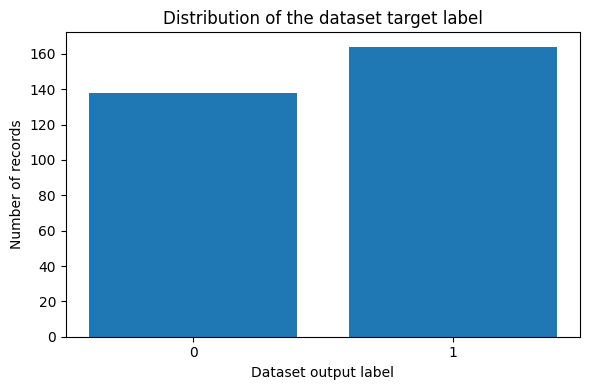

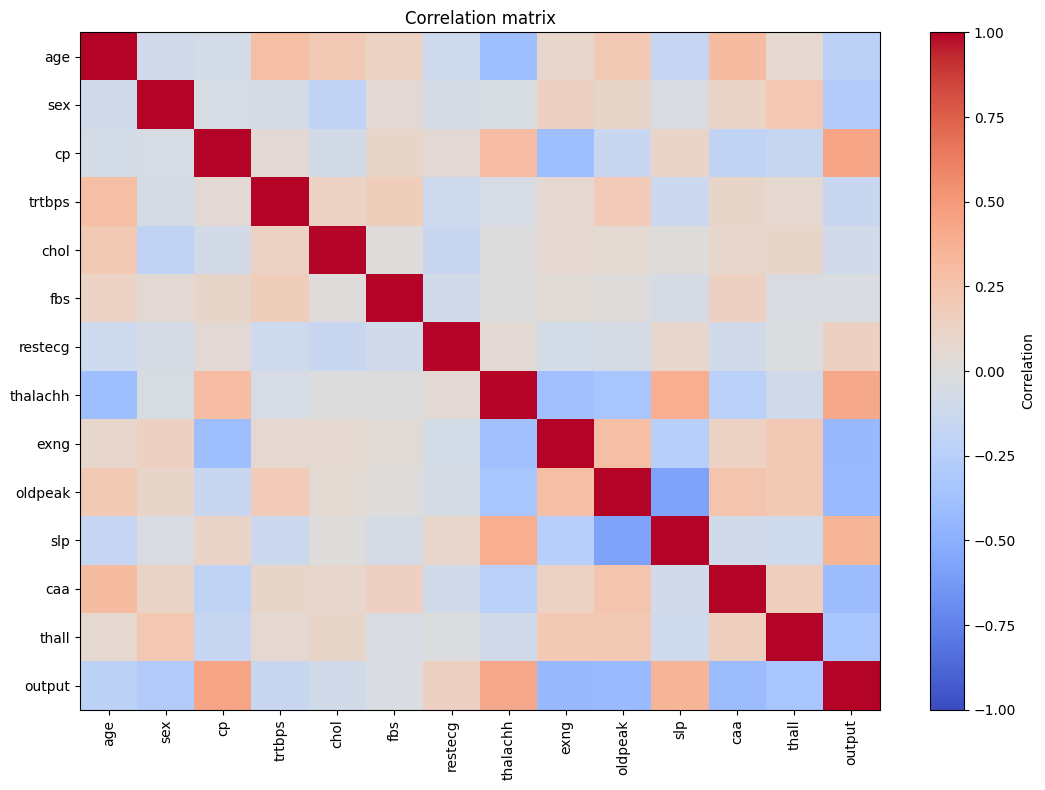

In [3]:
target_counts = df[TARGET].value_counts().sort_index()
plt.figure(figsize=(6, 4))
plt.bar(target_counts.index.astype(str), target_counts.values)
plt.xlabel("Dataset output label")
plt.ylabel("Number of records")
plt.title("Distribution of the dataset target label")
plt.tight_layout()
plt.show()

numeric_corr = df.corr(numeric_only=True)
plt.figure(figsize=(11, 8))
plt.imshow(numeric_corr, aspect="auto", cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(numeric_corr.columns)), numeric_corr.columns, rotation=90)
plt.yticks(range(len(numeric_corr.columns)), numeric_corr.columns)
plt.title("Correlation matrix")
plt.tight_layout()
plt.show()

## 3. Define the feature types

The dataset uses numeric codes for several categorical features. For the supervised models, we scale continuous measurements and one-hot encode categorical/discrete fields. This avoids treating category codes as if they were ordinary continuous measurements.

The same transformation is used for unsupervised exploration, but the output label is **not** included in clustering inputs.

In [4]:
if TARGET not in df.columns:
    raise ValueError(f"Missing target column: {TARGET}")

X = df.drop(columns=[TARGET]).copy()
y = df[TARGET].astype(int).copy()

continuous_features = ["age", "trtbps", "chol", "thalachh", "oldpeak"]
categorical_features = ["sex", "cp", "fbs", "restecg", "exng", "slp", "caa", "thall"]

missing_feature_names = (set(continuous_features) | set(categorical_features)) - set(X.columns)
if missing_feature_names:
    raise ValueError(f"Expected feature columns are missing: {sorted(missing_feature_names)}")

print("Number of records:", len(df))
print("Number of raw input features:", X.shape[1])
print("Continuous features:", continuous_features)
print("Categorical/discrete features:", categorical_features)
print("Target labels:", sorted(y.unique().tolist()))

Number of records: 302
Number of raw input features: 13
Continuous features: ['age', 'trtbps', 'chol', 'thalachh', 'oldpeak']
Categorical/discrete features: ['sex', 'cp', 'fbs', 'restecg', 'exng', 'slp', 'caa', 'thall']
Target labels: [0, 1]


# Part A — Unsupervised learning

## 4. Scale/encode the input features

Clustering uses distance or density, so feature representation matters. We use the feature transformer on `X` only. The target `y` is kept aside for optional post-hoc comparison, not for fitting the clusters.

Because this section is exploratory, the transformer is fitted to all feature rows. For a production evaluation, clustering parameters and transformations should be assessed on a separate dataset.

In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

# Compatibility with older and newer scikit-learn releases.
try:
    one_hot = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:
    one_hot = OneHotEncoder(handle_unknown="ignore", sparse=False)

unsupervised_preprocessor = ColumnTransformer(
    transformers=[
        ("continuous", StandardScaler(), continuous_features),
        ("categorical", one_hot, categorical_features),
    ],
    remainder="drop",
    verbose_feature_names_out=False
)

X_unsup = unsupervised_preprocessor.fit_transform(X)
X_unsup = np.asarray(X_unsup, dtype=float)

print("Raw feature shape:", X.shape)
print("Transformed feature shape:", X_unsup.shape)
print("Output label used to fit the transformer or clusters: No")

Raw feature shape: (302, 13)
Transformed feature shape: (302, 30)
Output label used to fit the transformer or clusters: No


## 5. PCA visualization

PCA creates new components that capture variation in the transformed features. The first two components make a 2D plot possible; they do not necessarily retain all information.

The label-coloured chart is only a visual comparison against the known labels after PCA is fitted. It does not train PCA using the labels.

PC1 explained variance: 24.47%
PC2 explained variance: 13.65%
Total variance explained by 2 components: 38.12%


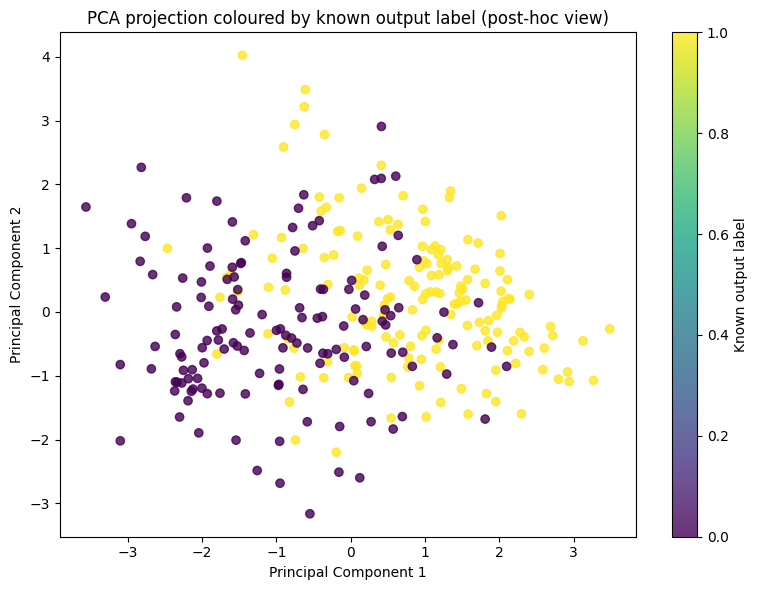

In [6]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_unsup)
explained = pca.explained_variance_ratio_

print(f"PC1 explained variance: {explained[0]:.2%}")
print(f"PC2 explained variance: {explained[1]:.2%}")
print(f"Total variance explained by 2 components: {explained.sum():.2%}")

plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, alpha=0.8)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA projection coloured by known output label (post-hoc view)")
plt.colorbar(scatter, label="Known output label")
plt.tight_layout()
plt.show()

## 6. K-Means clustering

K-Means requires the number of clusters in advance. We start with two clusters as an exploratory choice, not because the algorithm knows the medical meaning of either group. We report cluster sizes and a silhouette score when that score is defined.

K-Means cluster counts:


,records
cluster,
0,167
1,135


K-Means silhouette score: 0.1648
Adjusted Rand Index vs known labels (post-hoc comparison, not training): 0.2508


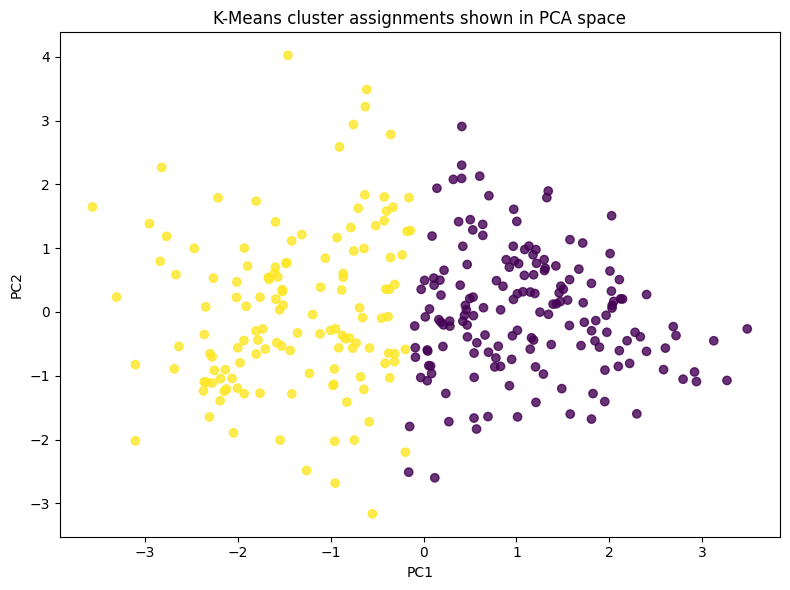

In [7]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

kmeans = KMeans(n_clusters=2, random_state=RANDOM_STATE, n_init=10)
kmeans_labels = kmeans.fit_predict(X_unsup)

print("K-Means cluster counts:")
display(pd.Series(kmeans_labels, name="cluster").value_counts().sort_index().to_frame("records"))

if len(np.unique(kmeans_labels)) > 1 and len(np.unique(kmeans_labels)) < len(kmeans_labels):
    print("K-Means silhouette score:", round(silhouette_score(X_unsup, kmeans_labels), 4))
else:
    print("Silhouette score is not defined for these assignments.")

print(
    "Adjusted Rand Index vs known labels (post-hoc comparison, not training):",
    round(adjusted_rand_score(y, kmeans_labels), 4)
)

plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans_labels, alpha=0.8)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("K-Means cluster assignments shown in PCA space")
plt.tight_layout()
plt.show()

## 7. DBSCAN clustering

DBSCAN identifies dense groups and can mark points as noise (`-1`). Its result depends strongly on `eps` and `min_samples`; therefore, we report the counts rather than claiming that any particular grouping is medically meaningful. The `eps` value below is an initial setting to inspect, not a guaranteed optimum.

DBSCAN cluster counts (label -1 means noise):


,records
cluster,
-1,56
0,246


DBSCAN noise points: 56
Adjusted Rand Index vs known labels (post-hoc comparison, not training): 0.0554
DBSCAN silhouette score on non-noise points is not defined: fewer than two clusters.


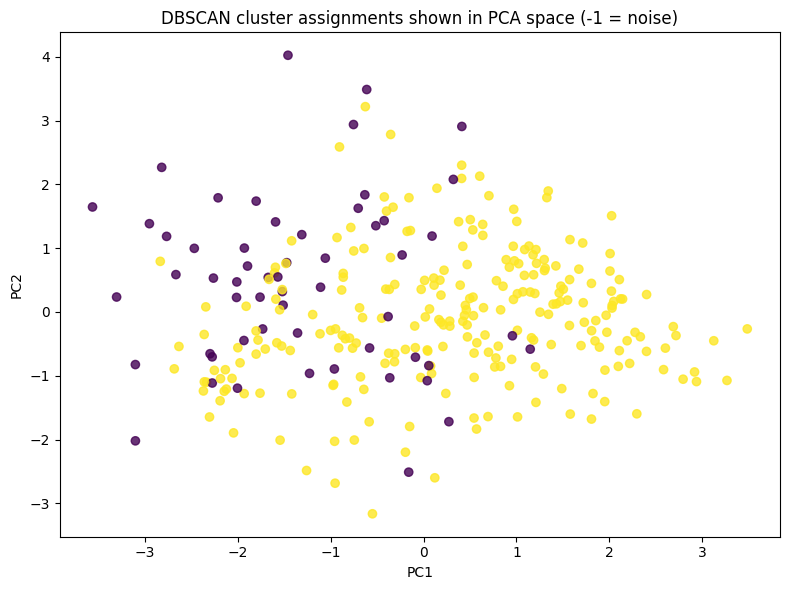

In [8]:
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(eps=2.5, min_samples=5)
dbscan_labels = dbscan.fit_predict(X_unsup)

dbscan_counts = pd.Series(dbscan_labels, name="cluster").value_counts().sort_index()
print("DBSCAN cluster counts (label -1 means noise):")
display(dbscan_counts.to_frame("records"))
print("DBSCAN noise points:", int(np.sum(dbscan_labels == -1)))
print(
    "Adjusted Rand Index vs known labels (post-hoc comparison, not training):",
    round(adjusted_rand_score(y, dbscan_labels), 4)
)

# Silhouette score on non-noise points only, if at least two clusters remain.
non_noise_mask = dbscan_labels != -1
non_noise_labels = dbscan_labels[non_noise_mask]
if len(non_noise_labels) > 1 and len(np.unique(non_noise_labels)) >= 2:
    print(
        "DBSCAN silhouette score on non-noise points:",
        round(silhouette_score(X_unsup[non_noise_mask], non_noise_labels), 4)
    )
else:
    print("DBSCAN silhouette score on non-noise points is not defined: fewer than two clusters.")

plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=dbscan_labels, alpha=0.8)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("DBSCAN cluster assignments shown in PCA space (-1 = noise)")
plt.tight_layout()
plt.show()

### Unsupervised-learning interpretation

- K-Means and DBSCAN are used to explore patterns; they do not directly predict a future heart attack.
- The silhouette score measures how separated clusters are under the selected representation and distance.
- Adjusted Rand Index compares cluster assignments with known labels after clustering. It is a descriptive comparison only; the labels were not used to fit the clusters.
- A high or low clustering score alone does not establish clinical usefulness.
- The data includes categorical/discrete fields, and one-hot encoding changes the distance geometry. Results should be interpreted as exploratory.

# Part B — Supervised learning

## 8. Split the data before fitting preprocessing

We use a stratified 60% training, 20% validation, and 20% test split. The training split is used for fitting models and cross-validation. The validation split is used for model comparison. The test split is held for the final evaluation.

In [9]:
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.40, stratify=y, random_state=RANDOM_STATE
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=RANDOM_STATE
)

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)
print("Index overlaps:",
      len(set(X_train.index) & set(X_val.index)),
      len(set(X_train.index) & set(X_test.index)),
      len(set(X_val.index) & set(X_test.index)))

Train: (181, 13) (181,)
Validation: (60, 13) (60,)
Test: (61, 13) (61,)
Index overlaps: 0 0 0


## 9. Build a preprocessing-and-model pipeline

The key correction is that preprocessing is placed inside each model pipeline. During cross-validation, the scaler and encoder are fitted separately inside each fold. This prevents preprocessing from learning information from a fold's validation rows.

In [10]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

def make_preprocessor():
    try:
        encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        encoder = OneHotEncoder(handle_unknown="ignore", sparse=False)
    return ColumnTransformer(
        transformers=[
            ("continuous", StandardScaler(), continuous_features),
            ("categorical", encoder, categorical_features),
        ],
        remainder="drop"
    )

def make_pipeline(classifier):
    return Pipeline([
        ("preprocessor", make_preprocessor()),
        ("classifier", classifier)
    ])

print("Pipeline structure: raw columns -> preprocessing -> classifier")

Pipeline structure: raw columns -> preprocessing -> classifier


## 10. Compare baseline classifiers on the validation set

This comparison includes a set of standard classifiers. Metrics are calculated on the validation set only. The positive class is assumed to be label `1` in the supplied dataset.

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,SVM - Linear,0.7833,0.7381,0.9394,0.8267,0.9024
1,Logistic Regression,0.8333,0.7949,0.9394,0.8611,0.8810
2,SVM - RBF,0.8000,0.7838,0.8788,0.8286,0.8765
3,SVM - Polynomial,0.7833,0.7778,0.8485,0.8116,0.8608
4,Random Forest,0.7833,0.7381,0.9394,0.8267,0.8474
5,Bagging,0.8000,0.7561,0.9394,0.8378,0.8423
6,Neural Network,0.8333,0.8108,0.9091,0.8571,0.8272
7,Decision Tree,0.7667,0.7436,0.8788,0.8056,0.7542


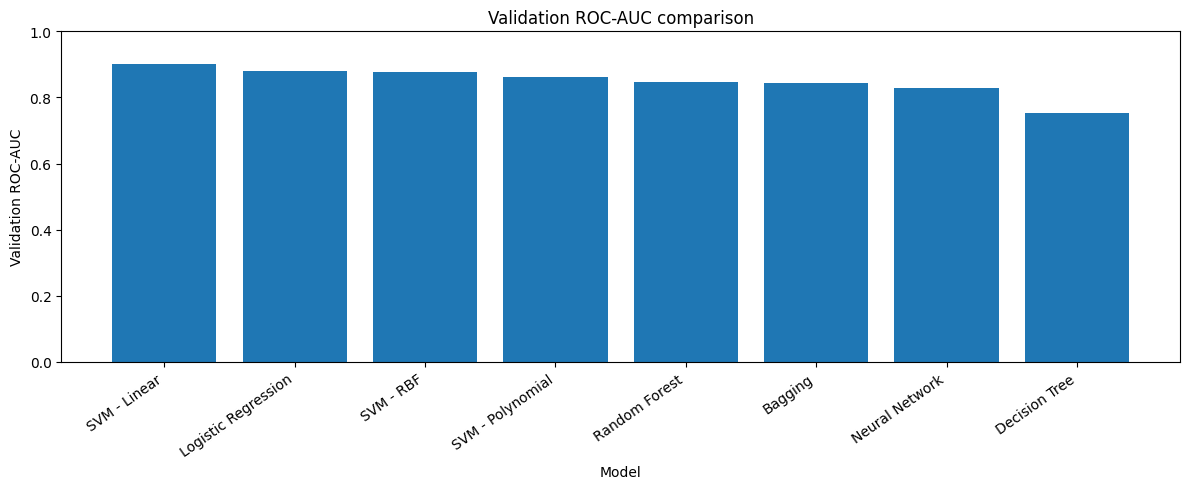

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, RocCurveDisplay
)

models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
    "SVM - Linear": SVC(kernel="linear", probability=True, random_state=RANDOM_STATE),
    "SVM - RBF": SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE),
    "SVM - Polynomial": SVC(kernel="poly", degree=3, probability=True, random_state=RANDOM_STATE),
    "Neural Network": MLPClassifier(
        hidden_layer_sizes=(32, 16), activation="relu", solver="adam",
        alpha=0.0001, learning_rate_init=0.001, max_iter=2000,
        random_state=RANDOM_STATE
    ),
}

# BaggingClassifier changed its argument name in newer sklearn releases.
try:
    bagging = BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
        n_estimators=100, random_state=RANDOM_STATE
    )
except TypeError:
    bagging = BaggingClassifier(
        base_estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
        n_estimators=100, random_state=RANDOM_STATE
    )
models["Bagging"] = bagging

validation_results = []
fitted_models = {}

for name, classifier in models.items():
    pipe = make_pipeline(clone(classifier))
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_val)
    prob = pipe.predict_proba(X_val)[:, 1]
    row = {
        "Model": name,
        "Accuracy": accuracy_score(y_val, pred),
        "Precision": precision_score(y_val, pred, zero_division=0),
        "Recall": recall_score(y_val, pred, zero_division=0),
        "F1 Score": f1_score(y_val, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_val, prob),
    }
    validation_results.append(row)
    fitted_models[name] = pipe

validation_results_df = pd.DataFrame(validation_results).sort_values(
    by="ROC-AUC", ascending=False
).reset_index(drop=True)
display(validation_results_df.round(4))

plt.figure(figsize=(12, 5))
plt.bar(validation_results_df["Model"], validation_results_df["ROC-AUC"])
plt.ylabel("Validation ROC-AUC")
plt.xlabel("Model")
plt.title("Validation ROC-AUC comparison")
plt.xticks(rotation=35, ha="right")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

## 11. Tune Random Forest and RBF SVM with cross-validation

GridSearchCV receives the complete pipeline, not preprocessed data. Therefore, every cross-validation fold fits its own preprocessing transformations. The test set is not used for parameter selection.

In [12]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

rf_pipeline = make_pipeline(RandomForestClassifier(random_state=RANDOM_STATE))
rf_grid = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [None, 5, 10],
    "classifier__min_samples_split": [2, 5],
}
rf_search = GridSearchCV(
    rf_pipeline, rf_grid, cv=cv, scoring="roc_auc", n_jobs=-1, refit=True
)
rf_search.fit(X_train, y_train)

svm_pipeline = make_pipeline(SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE))
svm_grid = {
    "classifier__C": [0.1, 1, 10],
    "classifier__gamma": ["scale", 0.01, 0.1],
}
svm_search = GridSearchCV(
    svm_pipeline, svm_grid, cv=cv, scoring="roc_auc", n_jobs=-1, refit=True
)
svm_search.fit(X_train, y_train)

print("Best Random Forest parameters:", rf_search.best_params_)
print("Random Forest mean CV ROC-AUC:", round(rf_search.best_score_, 4))
print("\nBest SVM parameters:", svm_search.best_params_)
print("SVM mean CV ROC-AUC:", round(svm_search.best_score_, 4))

Best Random Forest parameters: {'classifier__max_depth': 10, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 100}
Random Forest mean CV ROC-AUC: 0.9138

Best SVM parameters: {'classifier__C': 1, 'classifier__gamma': 0.01}
SVM mean CV ROC-AUC: 0.9216


## 12. Select using validation performance

We compare the tuned candidates on validation ROC-AUC, then select the candidate with the higher validation score. The test set remains untouched until the next section.

In [13]:
tuned_candidates = {
    "Tuned Random Forest": rf_search.best_estimator_,
    "Tuned SVM (RBF)": svm_search.best_estimator_,
}

validation_tuned_rows = []
for name, model in tuned_candidates.items():
    pred = model.predict(X_val)
    prob = model.predict_proba(X_val)[:, 1]
    validation_tuned_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, pred),
        "Precision": precision_score(y_val, pred, zero_division=0),
        "Recall": recall_score(y_val, pred, zero_division=0),
        "F1 Score": f1_score(y_val, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_val, prob),
    })

validation_tuned_df = pd.DataFrame(validation_tuned_rows).sort_values(
    "ROC-AUC", ascending=False
).reset_index(drop=True)
display(validation_tuned_df.round(4))

selected_name = validation_tuned_df.loc[0, "Model"]
selected_model = tuned_candidates[selected_name]
print("Selected model based on validation ROC-AUC:", selected_name)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Tuned SVM (RBF),0.7833,0.7381,0.9394,0.8267,0.8608
1,Tuned Random Forest,0.7833,0.7381,0.9394,0.8267,0.8485


Selected model based on validation ROC-AUC: Tuned SVM (RBF)


## 13. Final test evaluation

This is the final held-out evaluation for the selected model. The test metrics should be reported as estimates from this particular small dataset, not as a guarantee of real-world medical performance.

,Selected Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Tuned SVM (RBF),0.8361,0.8108,0.9091,0.8571,0.9351


Classification report:
              precision    recall  f1-score   support

           0       0.88      0.75      0.81        28
           1       0.81      0.91      0.86        33

    accuracy                           0.84        61
   macro avg       0.84      0.83      0.83        61
weighted avg       0.84      0.84      0.83        61



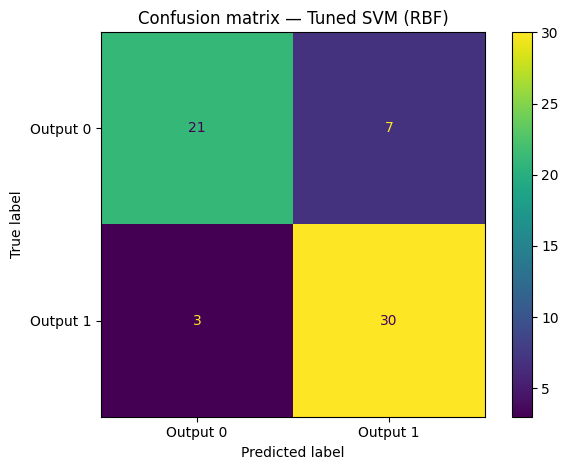

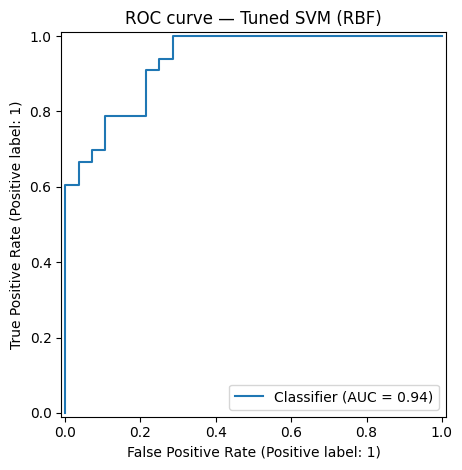

In [14]:
test_pred = selected_model.predict(X_test)
test_prob = selected_model.predict_proba(X_test)[:, 1]

test_results = pd.DataFrame([{
    "Selected Model": selected_name,
    "Accuracy": accuracy_score(y_test, test_pred),
    "Precision": precision_score(y_test, test_pred, zero_division=0),
    "Recall": recall_score(y_test, test_pred, zero_division=0),
    "F1 Score": f1_score(y_test, test_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, test_prob),
}])
display(test_results.round(4))

print("Classification report:")
print(classification_report(y_test, test_pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test, test_pred, display_labels=["Output 0", "Output 1"], cmap=None
)
plt.title(f"Confusion matrix — {selected_name}")
plt.tight_layout()
plt.show()

RocCurveDisplay.from_predictions(y_test, test_prob)
plt.title(f"ROC curve — {selected_name}")
plt.tight_layout()
plt.show()

## 14. Save the complete pipeline

Unlike saving only the classifier, this saves the fitted preprocessor and classifier together. At prediction time, pass a DataFrame containing the original 13 input columns; do not manually scale or one-hot encode the row first.

In [15]:
import joblib

MODEL_PATH = "heart_attack_prediction_model.pkl"
joblib.dump(selected_model, MODEL_PATH)
print("Saved complete pipeline to:", MODEL_PATH)
print("Saved object type:", type(selected_model).__name__)
print("Raw feature columns expected:", list(X.columns))

Saved complete pipeline to: heart_attack_prediction_model.pkl
Saved object type: Pipeline
Raw feature columns expected: ['age', 'sex', 'cp', 'trtbps', 'chol', 'fbs', 'restecg', 'thalachh', 'exng', 'oldpeak', 'slp', 'caa', 'thall']


# Part C — Final demonstration

## 15. Predict for a sample input

This is only an example record for demonstrating the pipeline. It is not medical advice and must not be used to make decisions about a real person's health.

In [16]:
sample_patient = pd.DataFrame([{
    "age": 55,
    "sex": 1,
    "cp": 2,
    "trtbps": 140,
    "chol": 250,
    "fbs": 0,
    "restecg": 1,
    "thalachh": 150,
    "exng": 0,
    "oldpeak": 1.0,
    "slp": 1,
    "caa": 0,
    "thall": 2
}], columns=X.columns)

loaded_model = joblib.load(MODEL_PATH)
prediction = int(loaded_model.predict(sample_patient)[0])
probabilities = loaded_model.predict_proba(sample_patient)[0]
classes = list(loaded_model.named_steps["classifier"].classes_)
positive_index = classes.index(1) if 1 in classes else None

print("Sample patient input:")
display(sample_patient)
print("Predicted dataset output label:", prediction)
if positive_index is not None:
    print(f"Model probability estimate for label 1: {probabilities[positive_index]:.3f}")

if prediction == 1:
    print("Demo interpretation: model predicts dataset label 1.")
else:
    print("Demo interpretation: model predicts dataset label 0.")

print("\nReminder: this is a classroom demonstration, not a clinically validated medical tool.")

Sample patient input:


,age,sex,cp,trtbps,chol,fbs,restecg,thalachh,exng,oldpeak,slp,caa,thall
0,55,1,2,140,250,0,1,150,0,1.0,1,0,2


Predicted dataset output label: 1
Model probability estimate for label 1: 0.834
Demo interpretation: model predicts dataset label 1.

Reminder: this is a classroom demonstration, not a clinically validated medical tool.


## 16. Conclusions and limitations

### What the project demonstrates
- Explores the dataset through basic quality checks and visualizations.
- Uses PCA, K-Means, and DBSCAN to explore structure without training those methods on the target label.
- Compares supervised classifiers and tunes Random Forest and RBF SVM with cross-validation.
- Uses a held-out test set for a final evaluation.
- Saves preprocessing and classification together in a single pipeline for consistent demonstration.

### Limitations
- The dataset is small and may not represent the wider population or current clinical practice.
- The dataset's `output` label should not be described as a calibrated probability of a future heart attack.
- Unsupervised clusters do not automatically correspond to medically meaningful risk groups.
- PCA's two-dimensional plot may preserve only part of the data's variance.
- Results depend on the dataset, split, preprocessing, model settings, and chosen metrics.
- External validation on independent, representative clinical data and expert oversight would be required before any real medical use.